In [1]:
cd ./wrkDir/s19/s19-1

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [2]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import  astropy.io.ascii as ascii
import catutil as utilities

import matplotlib
import matplotlib.pyplot as plt

import logging
logging.basicConfig(filename='6-ReGaus_selBias.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask_fdeltacut/'
pltDir=os.path.join(anaDir,'plot/selBias/')
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

Populating the interactive namespace from numpy and matplotlib


# Selection Bias of Resolution Cut
## Preparation

Read data and apply weak lensing. 90 degree rotation is applied for cuts except the resolution cut.

In [3]:
# Read catalog
dataP =   pd.read_hdf(inFname,mode='r')
data  =   dataP.to_records()

In [4]:
min_snr=10
max_snr=None
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

wlmask2    =   utilities.galaxy_selector(catalog=data,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=False,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e
dataU2=data[wlmask2]
weight2=utilities.get_weight_model(dataU2)*dataU2['weight']

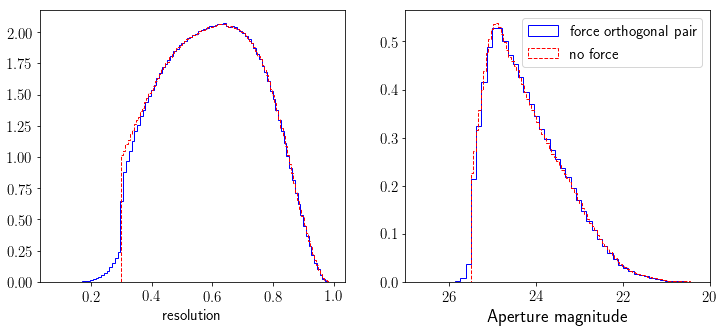

In [5]:
if True:
    min_snr=10
    max_snr=None
    max_magA10=25.5
    min_res=0.3
    max_mag=24.5
    max_logb=-0.38
    max_sigma_e=0.4
    max_e=2.

    wlmask    =   utilities.galaxy_selector(catalog=data,
                    min_snr=min_snr, #snr
                    max_snr=max_snr,
                    max_magA10=max_magA10, #magA10
                    min_res=min_res, #res
                    max_mag=max_mag, #mag
                    max_logb=max_logb,#logb
                    force_90_pair=True,
                    max_e=max_e,     #absE
                    max_sigma_e=max_sigma_e) #sigma_e
    dataU=data[wlmask]
    weight=utilities.get_weight_model(dataU)*dataU['weight']
    
    # 
    fig = plt.figure(figsize=(12,5))
    ax = fig.add_subplot(1,2,1)

    ax.hist(dataU['res'],bins=100,weights=weight,density=True,histtype='step',label=r'force orthogonal pair',color='blue')
    ax.hist(dataU2['res'],bins=100,weights=weight2,density=True,histtype='step',label='no force',color='red',ls='--')
    ax.set_xlabel('resolution',fontsize=15)

    ax = fig.add_subplot(1,2,2)
    ax.hist(dataU['magA10'],bins=100,weights=weight,density=True,histtype='step',label=r'force orthogonal pair',color='blue')
    ax.hist(dataU2['magA10'],bins=100,weights=weight2,density=True,histtype='step',label='no force',color='red',ls='--')
    ax.set_xlim(27,20)
    ax.set_xlabel('Aperture magnitude')
    plt.legend(fontsize=15,loc='upper right')
    plt.savefig(os.path.join(pltDir,'selBias_PDF_90rot_no90rot.eps'))
    plt.savefig(os.path.join(pltDir,'selBias_PDF_90rot_no90rot.png'))

In [9]:
def get_mc_bins(shearBinName,nbin_1d):
    outcomes=np.load(shearBinName)

    nsim   =   len(outcomes)
    psf_e1 =   np.zeros(nsim)
    psf_e2 =   np.zeros(nsim)
    weight =   np.zeros(nsim)
    g1_true=   np.zeros(nsim)
    g2_true=   np.zeros(nsim)
    g1_bins=   np.zeros((nbin_1d,nsim))
    g2_bins=   np.zeros((nbin_1d,nsim))
    sigma_g_bins=   np.zeros((nbin_1d,nsim))

    for iout,outcome in enumerate(outcomes):
        g1_true[iout]  =   outcome[0]
        g2_true[iout]  =   outcome[1]
        g1_bins[:,iout]  =   outcome[2]
        g2_bins[:,iout]  =   outcome[3]
        sigma_g_bins[:,iout]  =   outcome[4]
        psf_e1[iout]  =   outcome[5]
        psf_e2[iout]  =   outcome[6]
        weight[iout]  =   outcome[7]

    m1_bins    =   np.zeros(nbin_1d)
    a1_bins    =   np.zeros(nbin_1d)
    sigm1_bins =   np.zeros(nbin_1d)
    siga1_bins =   np.zeros(nbin_1d)

    # For each of the sliding bins in SNR/resolution.
    for j in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j],a1_bins[j], \
        sigm1_bins[j],siga1_bins[j]= \
            utilities.get_m_c_a(g1_bins[j,tmp_use],
                                g2_bins[j,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
    
    return m1_bins,a1_bins,sigm1_bins,siga1_bins

def makePlotSelBias(obsname,dataU,doPlot=False):
    nbin_1d=5
    shape_weight = utilities.get_weight_model(dataU)*dataU['weight']
    p_edges=np.zeros(nbin_1d)

    if obsname=="mag":
        xlabel='Cmodel Magnitude (lower limit)'
        cutplace=r'\rm{mag}=24.5'
        obs_cuts  =   np.linspace(20,22.5,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.025
        n_first_bin = np.sum(shape_weight[(obs >= 24.5 - bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs>=obs_cuts[i])]) * bin_size)
    elif obsname=="magA10":
        xlabel='Aperture Magnitude (lower limit)'
        cutplace=r'\rm{magA}=25.5'
        obs_cuts  =   np.linspace(23,24.5,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.025
        n_first_bin = np.sum(shape_weight[(obs >= 25.5 - bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs>=obs_cuts[i])]) * bin_size)
    elif obsname=="res":
        xlabel='Regaus resolution (upper limit)'
        cutplace=r'\rm{res}=0.3'
        obs_cuts  =   np.linspace(0.5,1.,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.01
        n_first_bin = np.sum(shape_weight[(obs <= 0.3 + bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs<=obs_cuts[i])]) * bin_size)
    elif obsname=="snr":
        xlabel='Cmodel SNR (upper limit)'
        cutplace=r'\rm{snr}=10'
        obs_cuts  =   np.linspace(80.,200.,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   1.
        n_first_bin = np.sum(shape_weight[(obs <= 10. + bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs<=obs_cuts[i])]) * bin_size)

    print(p_edges)
    shearBinName1=   os.path.join(pltDir,'shear_selbias_%s_%s.npy' %(obsname,obsname))
    shearBinName2=   os.path.join(pltDir,'shear_selbias_%s_%s_90rot.npy' %(obsname,obsname))

    m1,a1,sigm1,siga1=get_mc_bins(shearBinName1,nbin_1d)
    m2,a2,sigm2,siga2=get_mc_bins(shearBinName2,nbin_1d)

    if doPlot:
        fig = plt.figure(figsize=(12,5))
        ax = fig.add_subplot(1,2,1)
        ax.errorbar(obs_cuts, m1-m2,sigm1*np.sqrt(2.))
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$m_{\rm{sel}}$',fontsize=15)
        ax.set_title('Multiplicative bias')
        plt.grid()


        ax = fig.add_subplot(1,2,2)
        ax.errorbar(obs_cuts, a1-a2,siga1*np.sqrt(2.))
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$a_{\rm{sel}}$',fontsize=15)
        ax.set_title('Additive bias')
        plt.grid()
        plt.tight_layout()
        #plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

        fig = plt.figure(figsize=(12,5))
        ax = fig.add_subplot(1,2,1)
        ax.errorbar(obs_cuts, (m1-m2)/p_edges,sigm1*np.sqrt(2.)/p_edges)
        plt.xlabel(xlabel,fontsize=15)
        plt.ylabel(r'$m_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
        plt.title('Multiplicative bias of selection')
        plt.grid()


        ax = fig.add_subplot(1,2,2)
        ax.errorbar(obs_cuts, (a1-a2)/p_edges,siga1*np.sqrt(2.)/p_edges)
        plt.xlabel(xlabel,fontsize=15)
        plt.ylabel(r'$a_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
        plt.title('Additive bias of selection')
        plt.grid()
        plt.tight_layout()
        plt.savefig(os.path.join(pltDir,'selBias_%s.eps' %(obsname)))
    return obs_cuts,(m1-m2)*100,sigm1*np.sqrt(2.)*100,(a1-a2)*100,siga1*np.sqrt(2.)*100, p_edges

[0.24006924 0.26212607 0.29758285 0.35871524 0.4827677 ]


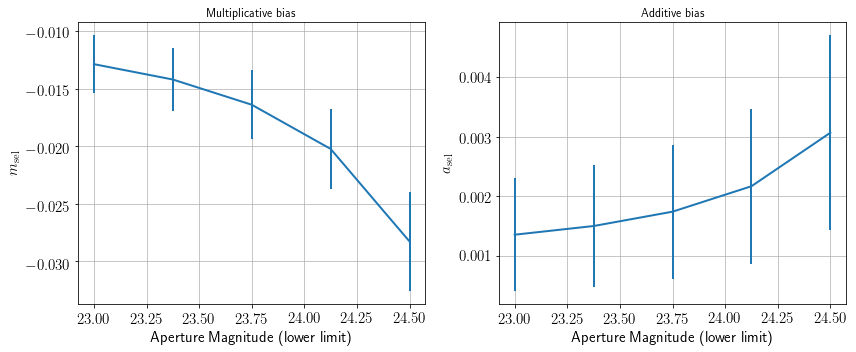

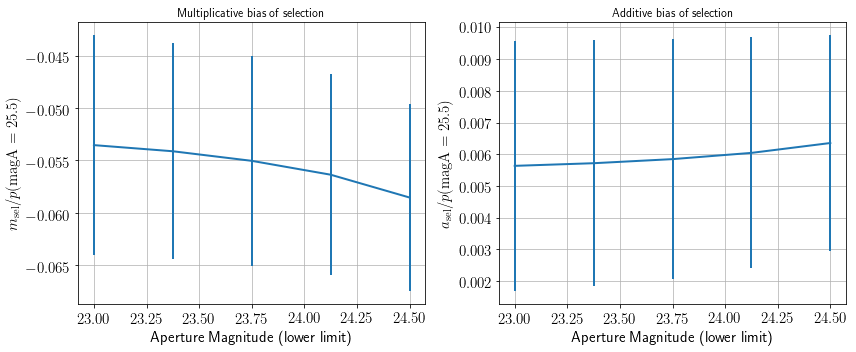

In [10]:
grid1,m_res1,sigm1,a_res1,siga1,pedge1=makePlotSelBias('magA10',dataU2,doPlot=True)

[3.38833071 1.85373922 1.27756515 1.05668215 1.02502921]


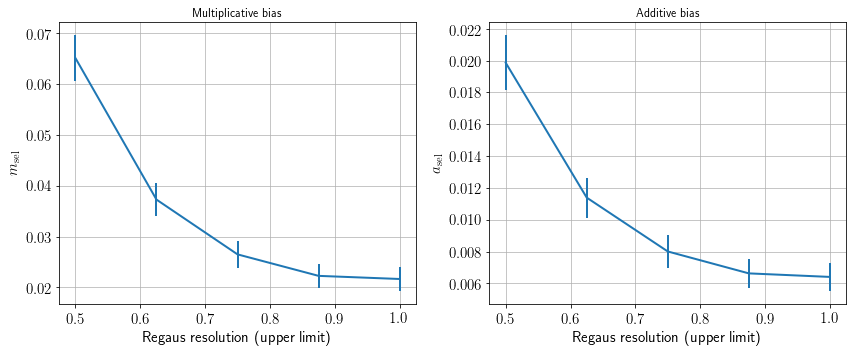

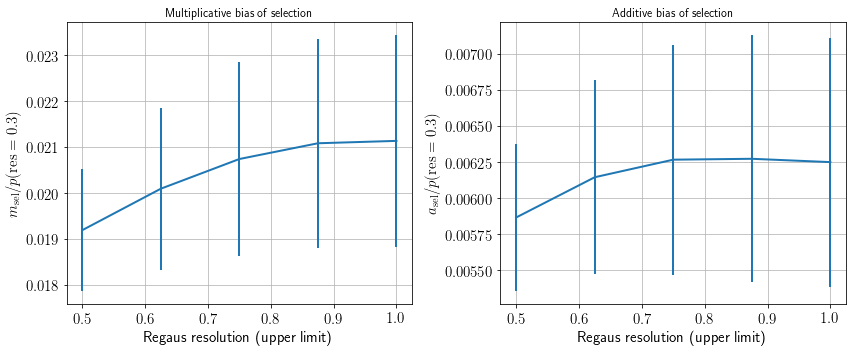

In [11]:
grid2,m_res2,sigm2,a_res2,siga2,pedge2=makePlotSelBias('res',dataU2,doPlot=True)

In [9]:
print('magA')
print(m_res1)
print(a_res1)
print('res')
print(m_res2)
print(a_res2)

magA
[-0.01285461 -0.014189   -0.01638004 -0.02021942 -0.02826246]
[0.0013529  0.00149899 0.0017401  0.00216813 0.00306817]
res
[0.06502895 0.03725068 0.02649853 0.02227961 0.02166545]
[0.0198663  0.01138638 0.00800294 0.00662577 0.00640366]


In [10]:
print('magA')
print(m_res1)
print(a_res1)
print('res')
print(m_res2)
print(a_res2)

magA
[-0.01285461 -0.014189   -0.01638004 -0.02021942 -0.02826246]
[0.0013529  0.00149899 0.0017401  0.00216813 0.00306817]
res
[0.06502895 0.03725068 0.02649853 0.02227961 0.02166545]
[0.0198663  0.01138638 0.00800294 0.00662577 0.00640366]


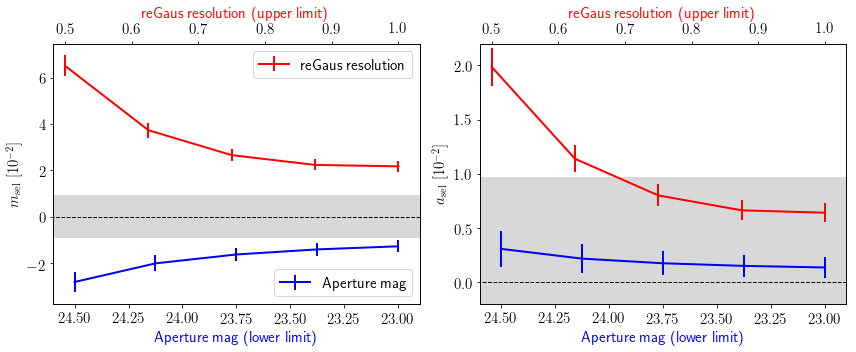

In [20]:
label1='Aperture mag'
label2='reGaus resolution'

fig = plt.figure(figsize=(12,5))
fig.set_rasterized(True) 

ax1 = fig.add_subplot(1,2,1)
ax1.set_rasterized(True)
ax1.errorbar(grid1,m_res1,sigm1,color='blue',label=label1)
x=np.linspace(22.8,24.6,20)
y00=-0.93*np.ones(len(x))
y11=0.93*np.ones(len(x))
ax1.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax1.plot(gref,np.zeros(len(gref)),c='black',linewidth=1.0,ls='--')
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$m_{\rm{sel}}~[10^{-2}]$',fontsize=15)
ax1.legend(fontsize=15,loc='lower right')
ax1.set_xlim(24.6,22.9)

ax2 = ax1.twiny()
ax2.errorbar(grid2, m_res2,sigm2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
ax2.legend(fontsize=15,loc='upper right')
#plt.grid()


ax1 = fig.add_subplot(1,2,2)
ax1.set_rasterized(True)
ax1.errorbar(grid1, a_res1,siga1,color='blue',label=label1)
ax1.plot(x,np.zeros(len(gref)),c='black',linewidth=1.0,ls='--')
y00=-0.97*np.ones(len(x))
y11=0.97*np.ones(len(x))
ax1.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$a_{\rm{sel}}~[10^{-2}]$',fontsize=15)
ax1.set_xlim(24.6,22.9)

ax2 = ax1.twiny()
ax2.errorbar(grid2, a_res2,siga2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
ax2.set_ylim(-0.2,2.2)
#plt.grid()

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'selBias_res_magA10.eps'),rasterized=True)

In [75]:
print('magA')
print('m')
print(m_res1/pedge1)
print(sigm1/pedge1)
print(np.average(m_res1/pedge1))
print('a')
print(a_res1/pedge1)
print(siga1/pedge1)
print(np.average(a_res1/pedge1))
print('res')
print('m')
print(m_res2/pedge2)
print(sigm2/pedge2)
print(np.average(m_res2/pedge2))
print('a')
print(a_res2/pedge2)
print(siga2/pedge2)
print(np.average(a_res2/pedge2))

magA
m
[-0.05354541 -0.05413045 -0.05504362 -0.05636621 -0.05854258]
[0.0104873  0.0103153  0.01001858 0.00960741 0.00891888]
-0.055525653470591664
a
[0.00563546 0.00571859 0.00584745 0.00604416 0.00635538]
[0.00394612 0.00388612 0.00378069 0.0036379  0.00339942]
0.005920206380492709
res
m
[0.01919203 0.02009489 0.02074143 0.02108449 0.02113642]
[0.00132426 0.00176026 0.00210167 0.00227733 0.00230107]
0.020449853253127696
a
[0.00586315 0.00614238 0.00626421 0.00627035 0.0062473 ]
[0.00051025 0.00067415 0.00079833 0.00085766 0.00086405]
0.0061574802606778915


In [8]:
shape_weight = utilities.get_weight_model(dataU2)*dataU2['weight']

In [29]:
bin_size  =   0.08
pedge1f=np.sum(shape_weight[(utilities.get_imag_A10(dataU2) >= 25.5 - bin_size)])/np.sum(shape_weight)/bin_size
print(pedge1f*-0.05854)
print(pedge1f*0.00636)

-0.01379430348756366
0.0014986636518774321


In [30]:
print(pedge1f)

0.23563893897443902
0.23563893897443902


In [37]:
bin_size  =   0.01
pedge2f=np.sum(shape_weight[(utilities.get_res(dataU2) <= 0.3 + bin_size)])/np.sum(shape_weight)/bin_size
print(pedge2f*0.01919)
print(pedge2f*0.00627)

0.01967031053199367
0.006426933144116746


In [38]:
print(pedge2f)

1.0250292095879976


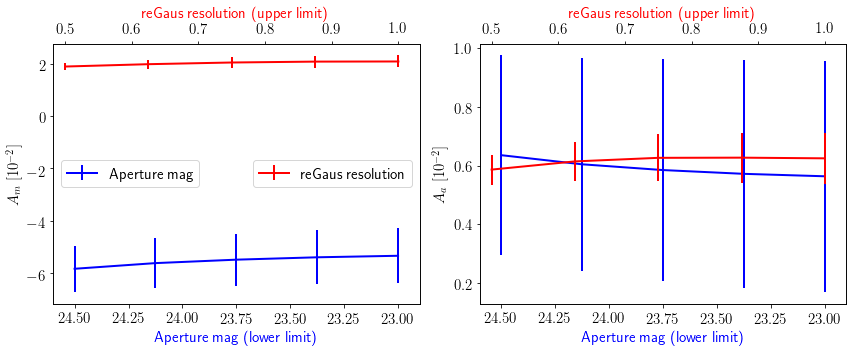

In [19]:
label1='Aperture mag'
label2='reGaus resolution'

fig = plt.figure(figsize=(12,5))
fig.set_rasterized(True) 


ax1 = fig.add_subplot(1,2,1)
ax1.set_rasterized(True)
ax1.errorbar(grid1, m_res1/pedge1,sigm1/pedge1,color='blue',label=label1)
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$A_{m}~[10^{-2}]$',fontsize=15)
ax1.set_xlim(24.6,22.9)
ax1.legend(fontsize=15,loc='center left')

ax2 = ax1.twiny()
ax2.errorbar(grid2, m_res2/pedge2,sigm2/pedge2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')
ax2.legend(fontsize=15,loc='center right')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
#plt.grid()



ax1 = fig.add_subplot(1,2,2)
ax1.set_rasterized(True)
ax1.errorbar(grid1, a_res1/pedge1,siga1/pedge1,color='blue',label=label1)
ax1.set_xlabel(label1+' (lower limit)',fontsize=15,color='blue')
ax1.set_ylabel(r'$A_{a}~[10^{-2}]$',fontsize=15)
ax1.set_xlim(24.6,22.9)

ax2 = ax1.twiny()
ax2.errorbar(grid2, a_res2/pedge2,siga2/pedge2,color='red',label=label2)
ax2.set_xlabel(label2+' (upper limit)',fontsize=15,color='red')

left, right = ax2.get_xlim()
dd=np.abs((right-left)/80.)
ax2.set_xlim(left+dd,right+dd)
#plt.grid()

plt.tight_layout()
plt.savefig(os.path.join(pltDir,'selBias_ratio_res_magA10.eps'),rasterized=True)

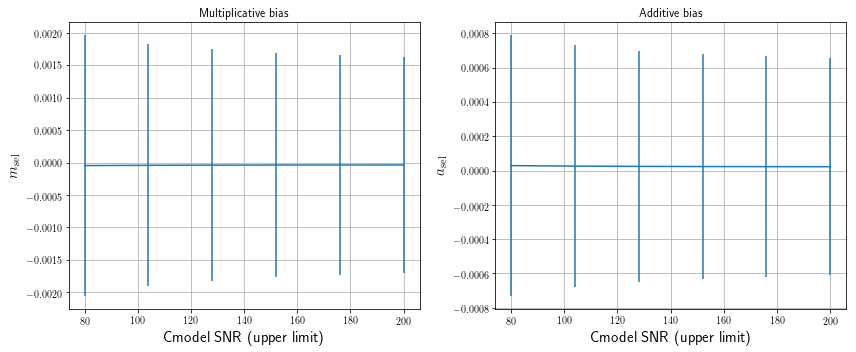

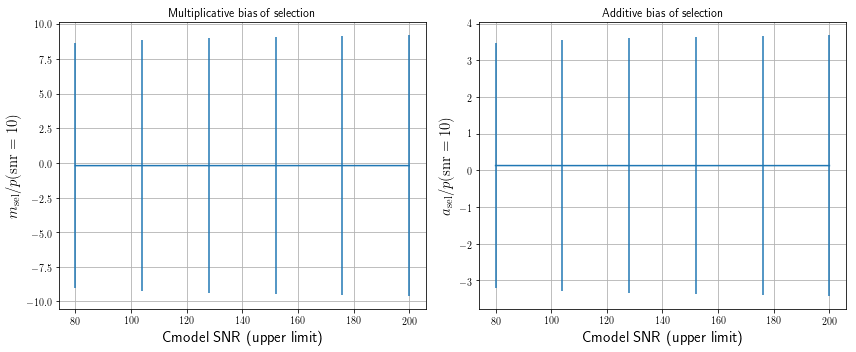

In [36]:
makePlotSelBias('snr',dataU2,doPlot=True)

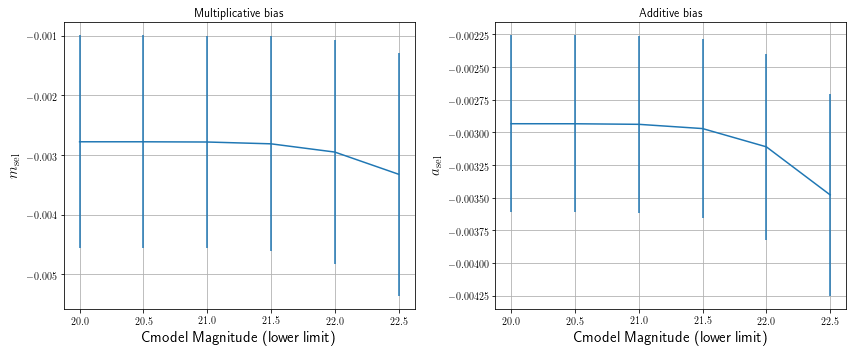

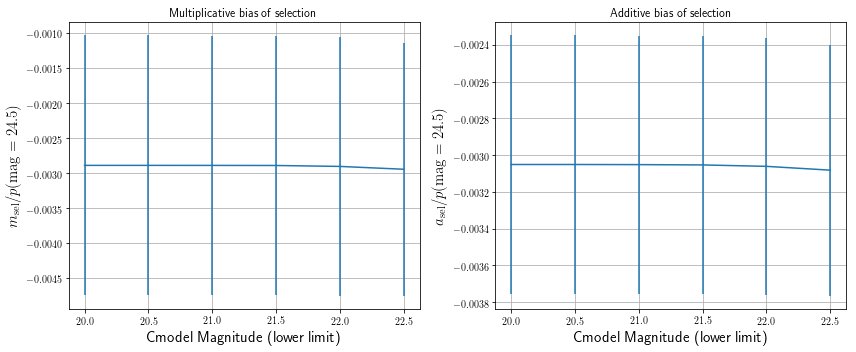

In [37]:
makePlotSelBias('mag',dataU2,doPlot=True)

## S16A Estimation
$$A= 0.00865\pm 0.0026$$

In [9]:
def get_res(catalog):
    """
    This utility returns the i-band resolution of the objects in the data or
    simulation catalog. Does not apply any cuts and returns NaNs for invalid
    values.
    """
    if 'res' in catalog.dtype.names:
        return catalog['res']
    elif 'i_hsmshaperegauss_resolution' in catalog.dtype.names:   #s18 & s19
        resolution  =   catalog['i_hsmshaperegauss_resolution']
    elif 'ishape_hsm_regauss_resolution' in catalog.dtype.names:  #s15
        resolution  =   catalog['ishape_hsm_regauss_resolution']
    elif 'ext_shapeHSM_HsmShapeRegauss_resolution' in catalog.dtype.names:#pipe 7
        resolution  =   catalog['ext_shapeHSM_HsmShapeRegauss_resolution']
    else:
        resolution  =   np.empty(len(catalog))
        resolution.fill(np.nan)
    return resolution

def get_imag_A10(catalog):
    """
    This utility returns the i-band aperture magnitude of the objects in the data or
    simulation catalog. Does not apply any cuts and returns NaNs for invalid
    values.
    """
    if 'magA10' in catalog.dtype.names:
        return catalog['magA10']
    elif 'i_apertureflux_10_mag' in catalog.dtype.names: #s18 s19
        magnitude   =   catalog['i_apertureflux_10_mag']
    elif 'base_CircularApertureFlux_3_0_instFlux' in catalog.dtype.names: #pipe 7
        magnitude   =   -2.5 * np.log10(catalog['base_CircularApertureFlux_3_0_instFlux']) + 27.
    else:
        magnitude   =   np.empty(len(catalog))
        magnitude.fill(np.nan)
    return magnitude


def get_psf_ellip(catalog):
    """
    This utility gets the PSF ellipticity (distortion) from a data or sims
    catalog.  It does not impose flag cuts, but rather assumes that has already
    been done

    Parameters:
    ----------
    catalog: array_like
        input galaxy catalog

    Returns:
    e1_psf: array_like
        the first component of ellipticity
    e2_psf: array_like
        the second component of ellipticity
    -------
    """
    if 'i_sdssshape_psf_shape11' in catalog.dtype.names:
        psf_mxx = catalog['i_sdssshape_psf_shape11']
        psf_myy = catalog['i_sdssshape_psf_shape22']
        psf_mxy = catalog['i_sdssshape_psf_shape12']
    else:
        raise ValueError("Do not have PSF shape measurement columns")

    return (psf_mxx - psf_myy) / (psf_mxx + psf_myy), 2. * \
        psf_mxy / (psf_mxx + psf_myy)

def get_selection_bias(weight,magA10,res):
    """
    This utility gets the selection bias (multiplicative and additive)

    Parameters:
    ----------
    weight: array_like
        Weight for dataset.  E.g., lensing shape weight, Sigma_c^-2 weight, ...
    res: array_like
        Resolution factor for dataset
    magA10: array_like
        aperture magnitude (1 arcsec) for dataset

    Returns:
    -------
    m_sel (float) :
        Multiplicative edge-selection bias
    a_sel (float) :
        additive edge-selection bias (c1)
    m_sel_err (float) :
        1-sigma uncertainty in m_sel
    a_sel_err (float) :
        1-sigma uncertainty in a_sel
    """

    if not(np.all(np.isfinite(weight))):
        raise ValueError("Non-finite weight")
    if not(np.all(weight) >= 0.0):
        raise ValueError("Negative weight")
    wSum    =   np.sum(weight)

    bin_magA=   0.025
    # magA10=   get_imag_A10(data)
    pedgeM  =   np.sum(weight[(magA10>= 25.5-bin_magA)])/wSum/bin_magA

    bin_res =   0.01
    # res   =   get_ires(data)
    pedgeR  =   np.sum(weight[(res<= 0.3+bin_res)])/wSum/bin_res
    m_sel   =   -0.059*pedgeM+0.019*pedgeR
    a_sel   =   0.0064*pedgeM+0.0063*pedgeR

    # assume the error for 2 cuts are independent.
    m_err   =   np.sqrt((0.0089*pedgeM)**2.+(0.0013*pedgeR)**2.)
    a_err   =   np.sqrt((0.0034*pedgeM)**2.+(0.0009*pedgeR)**2.)
    return m_sel,a_sel,m_err,a_err

In [ ]:
import gc
for fieldname in utilities.field_names:
    print(fieldname)
    gc.collect()
    break

In [10]:
#data=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/%s_no_m.fits'%fieldname)
weight=data['i_hsmshaperegauss_derived_weight']
magA10=data['i_apertureflux_10_mag']
res=data['i_hsmshaperegauss_resolution']
print(get_selection_bias(weight,magA10,res))

(0.011863334473183254, 0.009579871070540915, 0.002569217715670881, 0.0013838227701142333)


(26, 22.0)

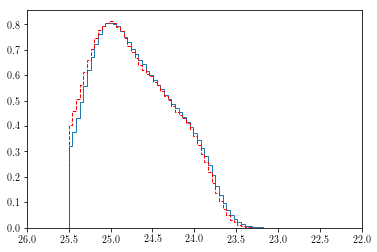

In [70]:
fieldname='WIDE12H'
data=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/%s_no_m.fits'%fieldname)
mask=(data['i_cmodel_flux']/data['i_cmodel_fluxerr']<80)
plt.hist(data[mask]['i_apertureflux_10_mag'],bins=80,density=True,histtype='step',range=[22.,25.5])
mask=dataU2['fieldname']==fieldname
mask&=(dataU2['snr']<80)
plt.hist(dataU2[mask]['magA10'],bins=80,weights=dataU2[mask]['weight'],density=True,histtype='step',color='red',ls='--',range=[22.,25.5])
plt.xlim(26,22.)